
# Geração de Base Sintética com Storytelling - Loja TechShop

Este notebook tem como objetivo gerar uma base de dados fictícia de uma loja online chamada **TechShop**, que vende produtos de tecnologia e móveis para home office.

O storytelling dessa base envolve:
- Sazonalidade de vendas, com picos em novembro (Black Friday) e dezembro (Natal).
- Descontos mais agressivos no mês de novembro.
- Preferência dos clientes por meios de pagamento como Pix e Cartão.
- Cancelamentos mais frequentes em boletos.
- Produtos como notebooks, smartphones e cadeiras gamer são os mais vendidos.


## 🔧 Instalar e importar bibliotecas

In [4]:

!pip install faker

from faker import Faker
import pandas as pd
import random
from datetime import datetime
import matplotlib.pyplot as plt
import os


## Gerar base de vendas com storytelling

In [5]:

fake = Faker('pt_BR')

num_pedidos = 1000
num_clientes = 300

produtos_categorias = {
    'Notebook': 'Eletrônicos',
    'Smartphone': 'Eletrônicos',
    'Tablet': 'Eletrônicos',
    'Monitor': 'Eletrônicos',
    'Cadeira Gamer': 'Móveis',
    'Mesa Escritório': 'Móveis',
    'Fone de Ouvido': 'Acessórios',
    'Mouse': 'Acessórios',
    'Teclado': 'Acessórios',
    'Webcam': 'Acessórios'
}

status_pedido = ['Em processamento', 'Enviado', 'Entregue', 'Cancelado']
meios_pagamento = ['Cartão de Crédito', 'Boleto Bancário', 'Pix', 'Transferência Bancária']

clientes = [fake.uuid4() for _ in range(num_clientes)]

data = []

for i in range(1, num_pedidos + 1):
    produto = random.choice(list(produtos_categorias.keys()))
    categoria = produtos_categorias[produto]
    quantidade = random.randint(1, 10)
    preco_unitario = round(random.uniform(100.0, 5000.0), 2)

    data_compra = fake.date_between(start_date='-1y', end_date='today')
    mes = data_compra.month

    if mes == 11:
        desconto = round(random.uniform(0.1, 0.3), 2)
    else:
        desconto = round(random.uniform(0.0, 0.15), 2)

    valor_total = round(quantidade * preco_unitario * (1 - desconto), 2)

    meio_pagamento = random.choices(
        population=meios_pagamento,
        weights=[0.5, 0.1, 0.3, 0.1],
        k=1
    )[0]

    if meio_pagamento == 'Boleto Bancário':
        status = random.choices(
            population=status_pedido,
            weights=[0.1, 0.1, 0.6, 0.2],
            k=1
        )[0]
    else:
        status = random.choices(
            population=status_pedido,
            weights=[0.2, 0.3, 0.45, 0.05],
            k=1
        )[0]

    data.append({
        'ID Pedido': f'PED{i:05}',
        'ID Cliente': random.choice(clientes),
        'Produto': produto,
        'Categoria': categoria,
        'Quantidade': quantidade,
        'Preço Unitário': preco_unitario,
        'Desconto (%)': desconto,
        'Valor Total': valor_total,
        'Data da Compra': data_compra,
        'Status do Pedido': status,
        'Meio de Pagamento': meio_pagamento
    })

df = pd.DataFrame(data)
df.head()


,ID Pedido,ID Cliente,Produto,Categoria,Quantidade,Preço Unitário,Desconto (%),Valor Total,Data da Compra,Status do Pedido,Meio de Pagamento
0,PED00001,8fe48aa6-416e-425e-bdfb-81ad394ca973,Fone de Ouvido,Acessórios,8,2561.46,0.02,20081.85,2025-04-08,Entregue,Cartão de Crédito
1,PED00002,a3f011af-aa53-46a8-9324-760046ab759a,Webcam,Acessórios,7,3446.30,0.08,22194.17,2024-08-16,Entregue,Cartão de Crédito
2,PED00003,6c9cd905-7879-442c-a7c9-766a32a09463,Mesa Escritório,Móveis,6,1373.02,0.22,6425.73,2024-11-25,Entregue,Cartão de Crédito
3,PED00004,bc0fdf03-3489-4e62-8d1e-0206f201b33d,Teclado,Acessórios,2,3420.57,0.12,6020.20,2024-11-29,Enviado,Cartão de Crédito
4,PED00005,44f64e43-7869-4f28-9e7c-9e25ac1a65b3,Webcam,Acessórios,2,1443.22,0.25,2164.83,2024-11-04,Entregue,Pix


## Análise Exploratória e Visualização

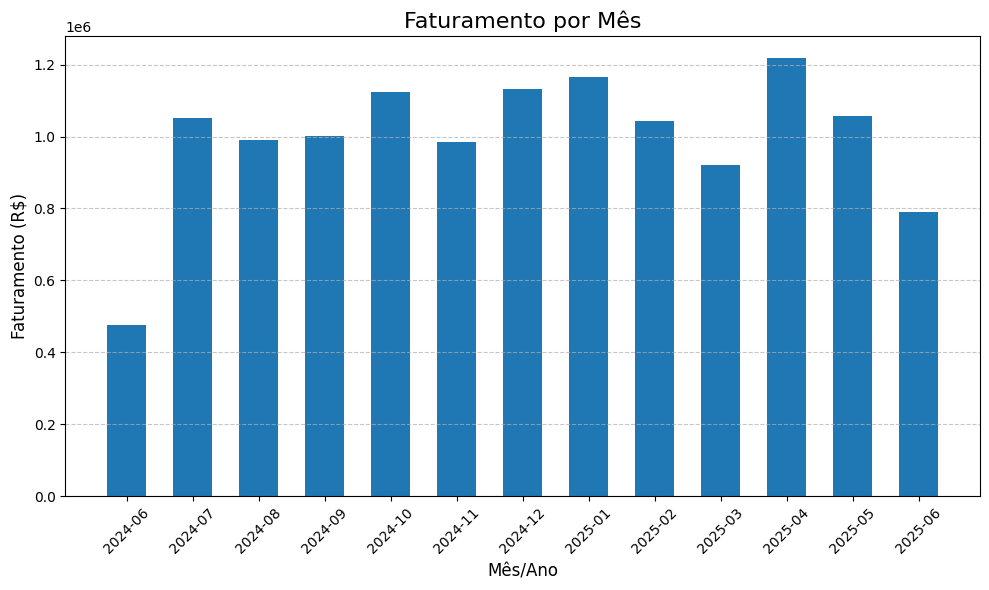

In [9]:
df['Data da Compra'] = pd.to_datetime(df['Data da Compra'], errors='coerce')
df = df.dropna(subset=['Data da Compra'])
df['AnoMes'] = df['Data da Compra'].dt.to_period('M').astype(str)
vendas_mes = df.groupby('AnoMes')['Valor Total'].sum().reset_index()
vendas_mes = vendas_mes.sort_values('AnoMes')

plt.figure(figsize=(10,6))
plt.bar(vendas_mes['AnoMes'], vendas_mes['Valor Total'], width=0.6)
plt.title('Faturamento por Mês', fontsize=16)
plt.xlabel('Mês/Ano', fontsize=12)
plt.ylabel('Faturamento (R$)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


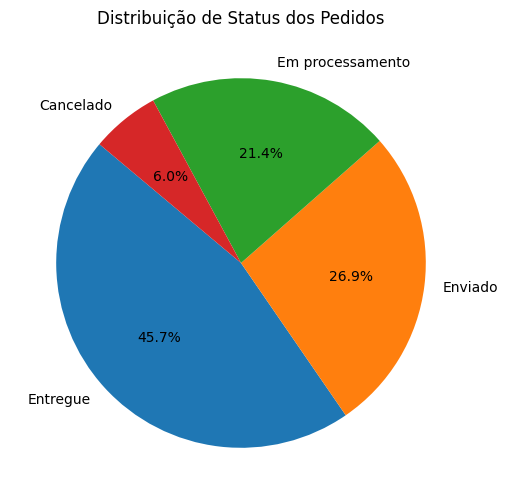

In [10]:

status_counts = df['Status do Pedido'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribuição de Status dos Pedidos')
plt.show()


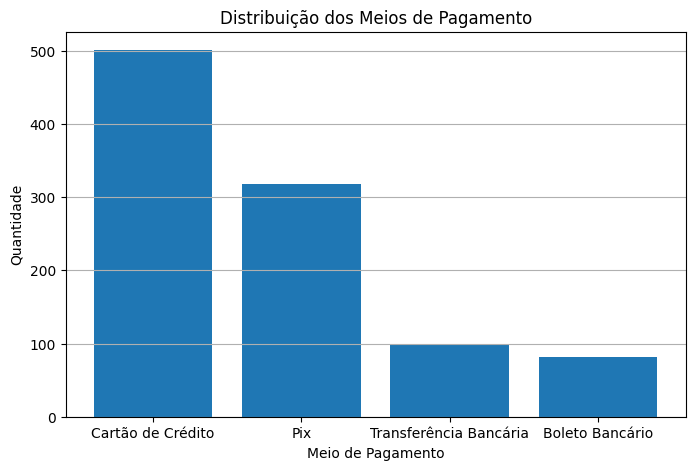

In [11]:

pagamento = df['Meio de Pagamento'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(pagamento.index, pagamento.values)
plt.title('Distribuição dos Meios de Pagamento')
plt.xlabel('Meio de Pagamento')
plt.ylabel('Quantidade')
plt.grid(axis='y')
plt.show()


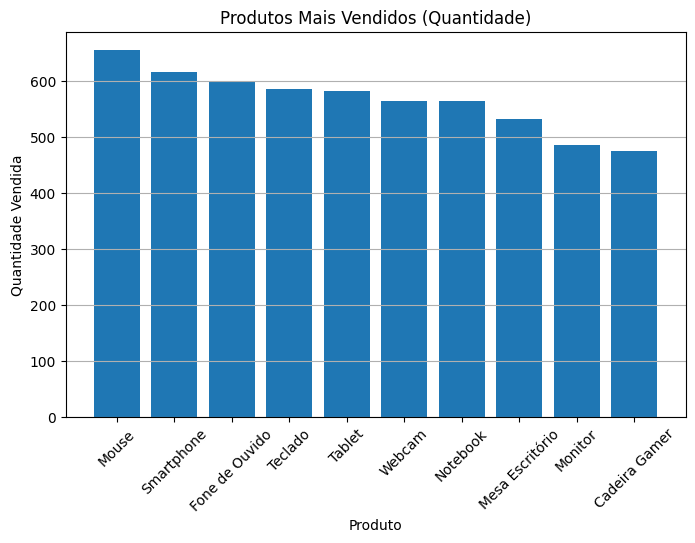

In [12]:

produtos = df.groupby('Produto')['Quantidade'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
plt.bar(produtos.index, produtos.values)
plt.title('Produtos Mais Vendidos (Quantidade)')
plt.xlabel('Produto')
plt.ylabel('Quantidade Vendida')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()


## Salvamento do Arquivo

In [13]:

os.makedirs('/content/meus_dados', exist_ok=True)

caminho = '/content/meus_dados/base_vendas.csv'
df.to_csv(caminho, index=False)

print(f'Arquivo salvo em {caminho}')


Arquivo salvo em /content/meus_dados/base_vendas.csv
